In [99]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [100]:
# Load CSV
try:
    df = pd.read_csv("../Datasets/csv/UAVUnderNormalCyberattacks.csv", low_memory=False)
except FileNotFoundError:
    print("Error: The file '../Datasets/csv/UAVUnderNormalCyberattacks.csv' was not found.")
    print("Please make sure the path is correct.")
    exit()

In [101]:
print(df.head())
print(df.info())

   timestamp_c frame.number frame.len frame.protocols wlan.duration wlan.ra  \
0   28105.9752           60        24               0             0       1   
1   28105.9755           61        24               0             0       1   
2  28107.09931           75       104               0             0       4   
3   28114.7857          122        86               2            44       1   
4  28114.88188          124        26               0            60       1   

  wlan.ta wlan.da wlan.sa wlan.bssid  ... tcp.options udp.srcport udp.dstport  \
0       1       1       1          0  ...           0           0           0   
1       1       1       1          0  ...           0           0           0   
2       1       4       1          0  ...           0           0           0   
3       0       1       0          0  ...           1           0           0   
4       0       1       0          0  ...           0           0           0   

  udp.length data.data data.len wlan.f

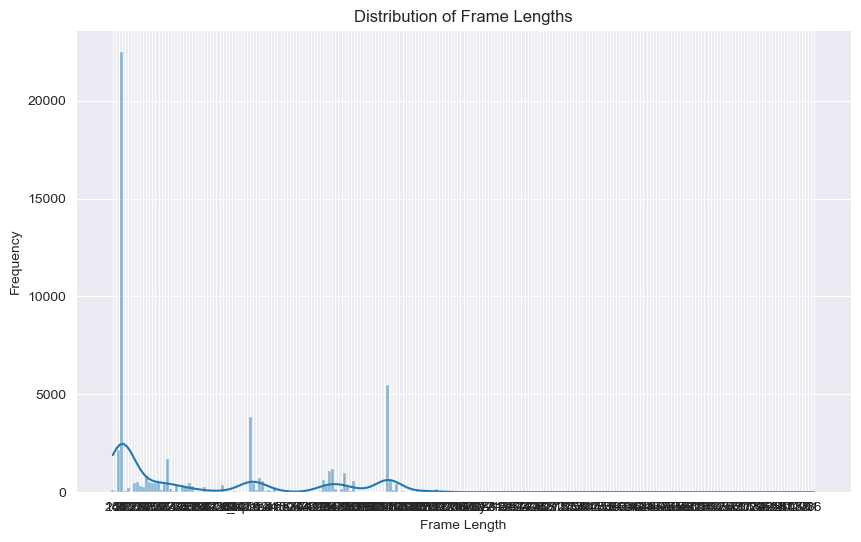

In [102]:
plt.figure(figsize=(10, 6))
sns.histplot(df['frame.len'].dropna(), kde=True)
plt.title('Distribution of Frame Lengths')
plt.xlabel('Frame Length')
plt.ylabel('Frequency')
plt.show()

In [103]:
df['class_filled'] = df['class']
df.loc[0:9425, 'class_filled'] = 'Benign'
df.loc[13717:25388, 'class_filled'] = 'DoS Attack'
df.loc[26363:38369, 'class_filled'] = 'Replay Attack'
df.loc[39344:45027, 'class_filled'] = 'Evil Twin'
df.loc[50502:54783, 'class_filled'] = 'FDI'
print(df['class_filled'].value_counts())
df = df[df['class_filled'] != 'class']

class_filled
Replay Attack    12007
DoS Attack       11672
Benign            9426
Evil Twin         5684
FDI               4281
class                2
Name: count, dtype: int64


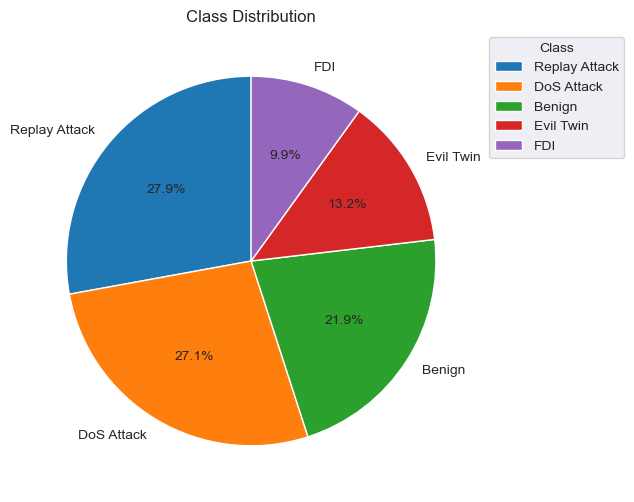

In [104]:
class_counts = df['class_filled'].value_counts()
class_counts.plot.pie(
    autopct='%1.1f%%',
    labels=class_counts.index,
    figsize=(6, 6),
    startangle=90
)
plt.title("Class Distribution")
plt.ylabel("")
plt.legend(class_counts.index, title="Class", bbox_to_anchor=(1, 1))
plt.show()

In [105]:
cyber_df = df.iloc[0:9426]
physical_df = df.iloc[9426:13717]
print("Cyber data sample:")
print(cyber_df.head())
print("Physical data sample:")
print(physical_df.head())

Cyber data sample:
   timestamp_c frame.number frame.len frame.protocols wlan.duration wlan.ra  \
0   28105.9752           60        24               0             0       1   
1   28105.9755           61        24               0             0       1   
2  28107.09931           75       104               0             0       4   
3   28114.7857          122        86               2            44       1   
4  28114.88188          124        26               0            60       1   

  wlan.ta wlan.da wlan.sa wlan.bssid  ... udp.srcport udp.dstport udp.length  \
0       1       1       1          0  ...           0           0          0   
1       1       1       1          0  ...           0           0          0   
2       1       4       1          0  ...           0           0          0   
3       0       1       0          0  ...           0           0          0   
4       0       1       0          0  ...           0           0          0   

  data.data data.len wlan